# Demonstration
This Jupyter notebooks is designed as a tutorial and visual demonstration of the inherent explainability of basic statistical and machine-learning models.

In [1]:
from __future__ import print_function
import numpy as np
import pandas as pd
import seaborn as sns
from importlib import reload
import matplotlib.pyplot as plt
from keras.preprocessing import sequence
from keras.utils import np_utils
from keras.models import Sequential
from keras.layers import Dense, Dropout, Activation, Embedding,LSTM, SimpleRNN, GRU,UpSampling1D, Layer, InputSpec, Input
from keras.utils.np_utils import to_categorical
from sklearn.metrics import (precision_score, recall_score,f1_score, accuracy_score,mean_squared_error,mean_absolute_error)
from sklearn import metrics
from sklearn.preprocessing import Normalizer, LabelEncoder, StandardScaler, OneHotEncoder,Binarizer
from keras import callbacks
from keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, CSVLogger
from keras import initializers, regularizers
from sklearn.utils import class_weight

## Data prep.

In [2]:
traindata = pd.read_csv('/kaggle/input/unsw-nb15/UNSW_NB15_training-set.csv')
testdata = pd.read_csv('/kaggle/input/unsw-nb15/UNSW_NB15_testing-set.csv')
traindata = traindata.drop('id', axis=1)
testdata = testdata.drop('id', axis=1)
print(traindata.shape, testdata.shape)

(82332, 44) (175341, 44)


In [3]:
traindata['service'].replace('-',np.nan,inplace=True)
testdata['service'].replace('-',np.nan,inplace=True)
print(traindata['service'].isna().sum()) # 47153 out of 82332
print(testdata['service'].isna().sum()) # 94168 out of 175341

47153
94168


In [4]:
traindata = traindata.drop(['service'],axis=1)
testdata = testdata.drop(['service'],axis=1)

In [5]:
def transfer_num_to_log(df):
    conv = []
    df_numeric = df.select_dtypes(include=[np.number])
    for feature in df_numeric.columns:
        if df_numeric[feature].nunique()>50:
            conv.append(feature)
            if df_numeric[feature].min()==0:
                df[feature] = np.log(df[feature]+1)
            else:
                df[feature] = np.log(df[feature])
    print("converted: ",conv)
    return df

traindata_log = transfer_num_to_log(traindata)
testdata_log = transfer_num_to_log(testdata)

converted:  ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'stcpb', 'dtcpb', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'response_body_len', 'ct_srv_src', 'ct_dst_src_ltm', 'ct_srv_dst']
converted:  ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'stcpb', 'dtcpb', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'response_body_len', 'ct_srv_src', 'ct_dst_src_ltm', 'ct_srv_dst']


In [6]:
for c in range(1,4):
    traindata.iloc[:,c] = LabelEncoder().fit_transform(traindata.iloc[:,c])
    testdata.iloc[:,c] = LabelEncoder().fit_transform(testdata.iloc[:,c])
    
from sklearn.model_selection import train_test_split
# Use last column for stratification (binary label)
traindata, _ = train_test_split(
    traindata,
    test_size=0.90,  # Keep 10%
    stratify=traindata.iloc[:, -1],  # Stratify on binary label
    random_state=42  # For reproducibility
)

train_x = traindata.iloc[:,0:41]
train_y_b = traindata.iloc[:,-1]
train_y_m = traindata.iloc[:,-2]
test_x = testdata.iloc[:,0:41]
test_y_b = testdata.iloc[:,-1]
test_y_m = testdata.iloc[:,-2]

## Visulization on the Inherent Explainability

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

The following approach provides a correlation-based visualization for explainability by illustrating the (linear) correlation between individual features and the target variable.

<Figure size 1152x1008 with 0 Axes>

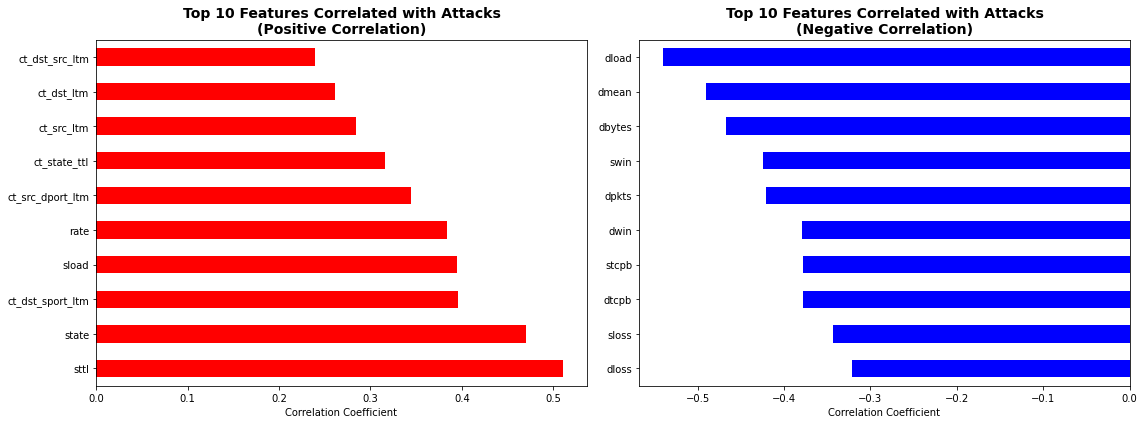

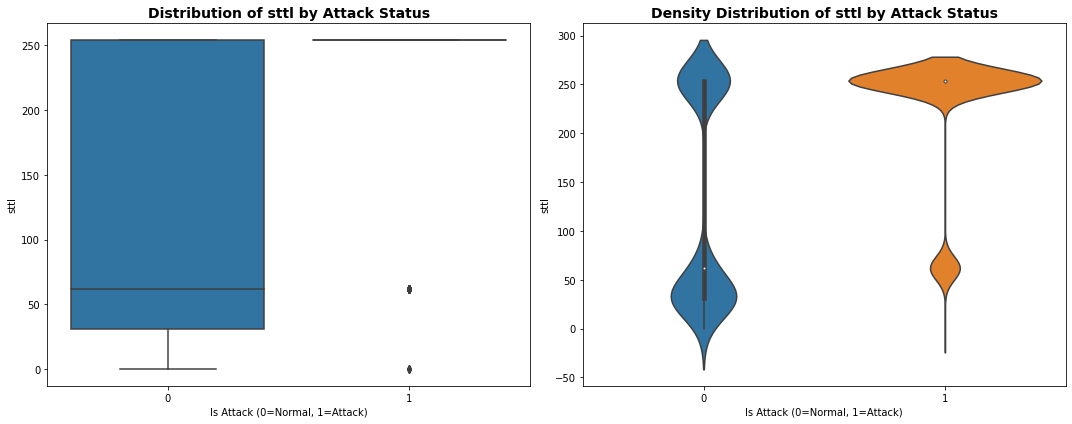

CORRELATION-BASED EXPLAINABILITY:
Most correlated feature: sttl (r = 0.511)


In [8]:
def correlation_analysis_visualization(train_x, train_y_b):
    """Visualize correlation-based analysis for explainability"""
    
    # Create a combined dataframe with target
    df_combined = train_x.copy()
    df_combined['is_attack'] = train_y_b
    
    # 1. Correlation heatmap with target
    plt.figure(figsize=(16, 14))
    correlation_with_target = df_combined.corr()['is_attack'].sort_values(ascending=False)
    top_corr_features = correlation_with_target.iloc[1:11]  # Exclude target itself
    bottom_corr_features = correlation_with_target.iloc[-10:]
    
    # Plot top and bottom correlations with target
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # Top positive correlations
    top_corr_features.plot(kind='barh', ax=ax1, color='red')
    ax1.set_title('Top 10 Features Correlated with Attacks\n(Positive Correlation)', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Correlation Coefficient')
    
    # Top negative correlations  
    bottom_corr_features.plot(kind='barh', ax=ax2, color='blue')
    ax2.set_title('Top 10 Features Correlated with Attacks\n(Negative Correlation)', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Correlation Coefficient')
    
    plt.tight_layout()
    plt.show()
    
    # 2. Feature relationships for top correlated features
    top_feature = correlation_with_target.index[1]  # Most correlated feature (excluding target itself)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # Box plot showing distribution differences
    sns.boxplot(x='is_attack', y=top_feature, data=df_combined, ax=ax1)
    ax1.set_title(f'Distribution of {top_feature} by Attack Status', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Is Attack (0=Normal, 1=Attack)')
    ax1.set_ylabel(top_feature)
    
    # Violin plot for better distribution visualization
    sns.violinplot(x='is_attack', y=top_feature, data=df_combined, ax=ax2)
    ax2.set_title(f'Density Distribution of {top_feature} by Attack Status', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Is Attack (0=Normal, 1=Attack)')
    ax2.set_ylabel(top_feature)
    
    plt.tight_layout()
    plt.show()
    
    print("CORRELATION-BASED EXPLAINABILITY:")
    print(f"Most correlated feature: {top_feature} (r = {correlation_with_target.iloc[1]:.3f})")
    
    return correlation_with_target
    
correlation_results = correlation_analysis_visualization(train_x, train_y_b)

For linear regression models, interpretability follows directly from the model structure: each feature’s contribution to the predicted attack probability is quantified by its coefficient (holding other variables constant), enabling straightforward assessment of feature importanc

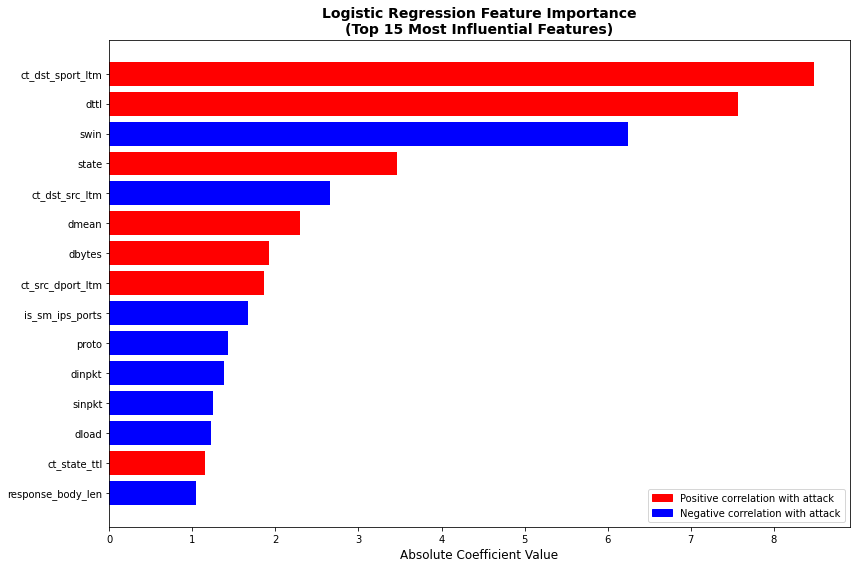

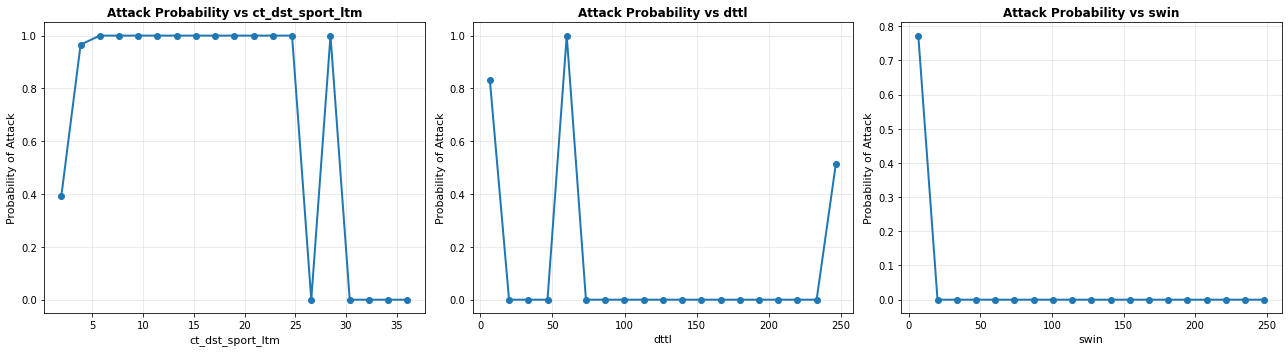

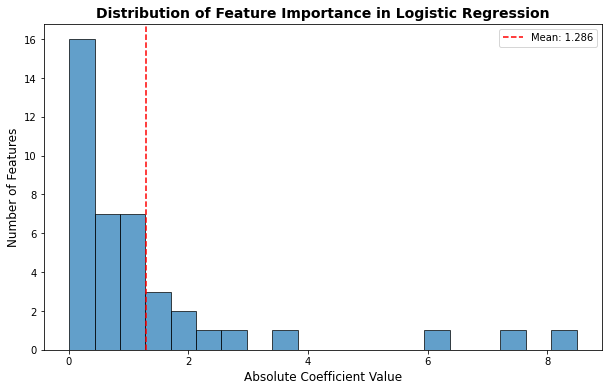


LOGISTIC REGRESSION EXPLAINABILITY:
Top 3 most important features for intrusion detection:
  ct_dst_sport_ltm: coefficient = 8.489
  dttl: coefficient = 7.567
  swin: coefficient = -6.241


In [9]:
def logistic_regression_visualization(train_x, train_y_b):
    """Train logistic regression and visualize feature importance for explainability"""
    
    # Preprocess the data
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(train_x)
    
    # Train logistic regression model
    lr_model = LogisticRegression(random_state=42, max_iter=1000)
    lr_model.fit(X_scaled, train_y_b)
    
    # Get feature importance (coefficients)
    feature_importance = pd.DataFrame({
        'feature': train_x.columns,
        'importance': np.abs(lr_model.coef_[0]),
        'direction': ['positive' if x > 0 else 'negative' for x in lr_model.coef_[0]]
    }).sort_values('importance', ascending=False)
    
    # 1. Feature importance plot
    plt.figure(figsize=(12, 8))
    top_features = feature_importance.head(15)
    
    colors = ['red' if dir == 'positive' else 'blue' for dir in top_features['direction']]
    bars = plt.barh(top_features['feature'], top_features['importance'], color=colors)
    plt.xlabel('Absolute Coefficient Value', fontsize=12)
    plt.title('Logistic Regression Feature Importance\n(Top 15 Most Influential Features)', fontsize=14, fontweight='bold')
    plt.gca().invert_yaxis()
    
    # Add legend
    import matplotlib.patches as mpatches
    red_patch = mpatches.Patch(color='red', label='Positive correlation with attack')
    blue_patch = mpatches.Patch(color='blue', label='Negative correlation with attack')
    plt.legend(handles=[red_patch, blue_patch], loc='lower right')
    
    plt.tight_layout()
    plt.show()
    
    # 2. Detailed analysis of top 3 features
    top_3_features = feature_importance.head(3)['feature'].tolist()
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for i, feature in enumerate(top_3_features):
        # Create bins for the feature
        feature_data = train_x[feature]
        bins = np.linspace(feature_data.min(), feature_data.max(), 20)
        
        # Calculate attack probability in each bin
        bin_centers = (bins[:-1] + bins[1:]) / 2
        attack_probs = []
        
        for j in range(len(bins)-1):
            mask = (feature_data >= bins[j]) & (feature_data < bins[j+1])
            if mask.sum() > 0:
                attack_prob = train_y_b[mask].mean()
            else:
                attack_prob = 0
            attack_probs.append(attack_prob)
        
        axes[i].plot(bin_centers, attack_probs, 'o-', linewidth=2, markersize=6)
        axes[i].set_xlabel(feature, fontsize=11)
        axes[i].set_ylabel('Probability of Attack', fontsize=11)
        axes[i].set_title(f'Attack Probability vs {feature}', fontweight='bold')
        axes[i].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 3. Coefficient magnitude distribution
    plt.figure(figsize=(10, 6))
    plt.hist(feature_importance['importance'], bins=20, edgecolor='black', alpha=0.7)
    plt.xlabel('Absolute Coefficient Value', fontsize=12)
    plt.ylabel('Number of Features', fontsize=12)
    plt.title('Distribution of Feature Importance in Logistic Regression', fontsize=14, fontweight='bold')
    plt.axvline(feature_importance['importance'].mean(), color='red', linestyle='--', 
                label=f'Mean: {feature_importance["importance"].mean():.3f}')
    plt.legend()
    plt.show()
    
    print("\nLOGISTIC REGRESSION EXPLAINABILITY:")
    print("Top 3 most important features for intrusion detection:")
    for i, row in feature_importance.head(3).iterrows():
        print(f"  {row['feature']}: coefficient = {lr_model.coef_[0][train_x.columns.get_loc(row['feature'])]:.3f}")
    
    return lr_model, feature_importance, scaler

lr_model, lr_importance, lr_scaler = logistic_regression_visualization(train_x, train_y_b)

Principal Component Analysis (PCA) performs dimensionality reduction by projecting the data onto a smaller set of components that preserve maximal variance. Although interpretation requires mapping component loadings back to the original features, PCA can still offer a quantitative view of feature relevance and yield a reasonable level of explainability.

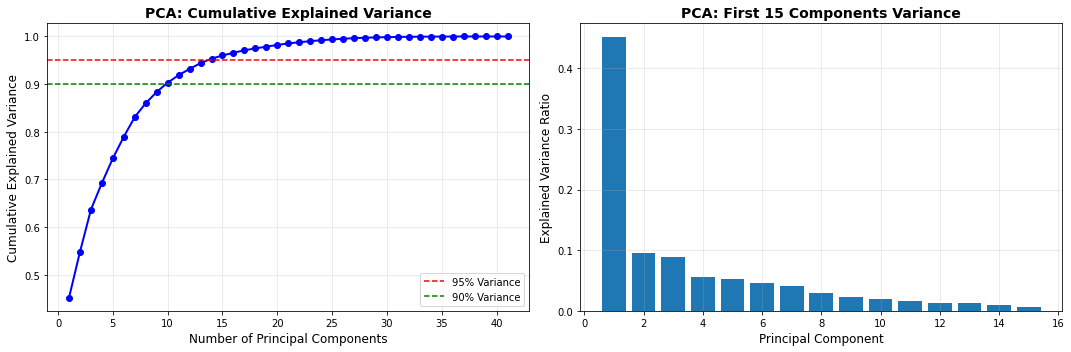

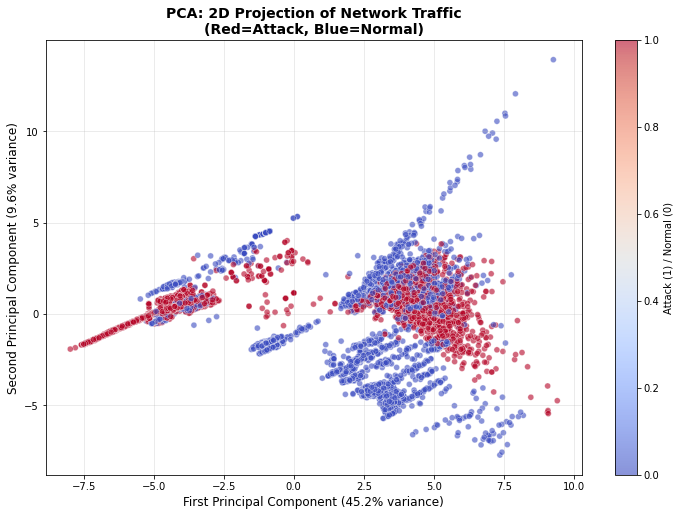

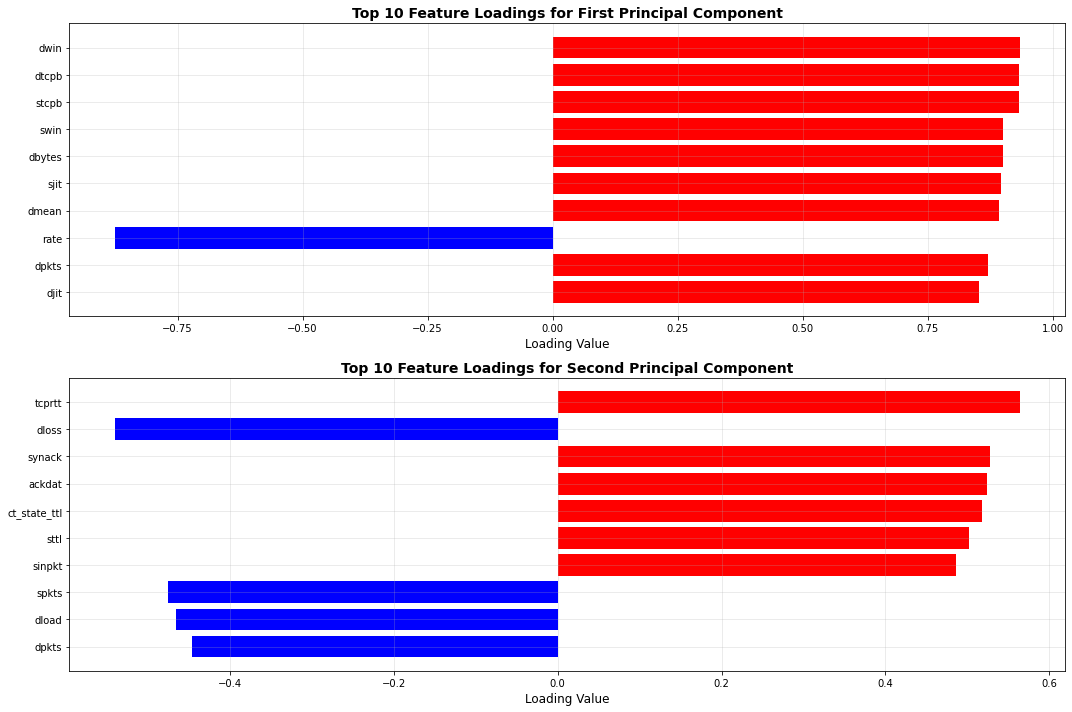


PCA EXPLAINABILITY:
• First PC explains 45.2% of variance
• First 2 PCs explain 54.8% of variance
• First 5 PCs explain 74.4% of variance
• Key features in PC1: ['dwin', 'dtcpb', 'stcpb']


In [10]:
def pca_visualization(train_x, train_y_b):
    """Visualize PCA for dimensionality reduction and explainability"""
    
    # Standardize the data
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(train_x)
    
    # Apply PCA
    pca = PCA()
    X_pca = pca.fit_transform(X_scaled)
    
    # 1. Explained variance ratio
    plt.figure(figsize=(15, 5))
    
    plt.subplot(1, 2, 1)
    cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
    plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, 'bo-', linewidth=2, markersize=6)
    plt.axhline(y=0.95, color='r', linestyle='--', label='95% Variance')
    plt.axhline(y=0.90, color='g', linestyle='--', label='90% Variance')
    plt.xlabel('Number of Principal Components', fontsize=12)
    plt.ylabel('Cumulative Explained Variance', fontsize=12)
    plt.title('PCA: Cumulative Explained Variance', fontsize=14, fontweight='bold')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # 2. Individual explained variance
    plt.subplot(1, 2, 2)
    components_to_show = 15
    plt.bar(range(1, components_to_show + 1), pca.explained_variance_ratio_[:components_to_show])
    plt.xlabel('Principal Component', fontsize=12)
    plt.ylabel('Explained Variance Ratio', fontsize=12)
    plt.title(f'PCA: First {components_to_show} Components Variance', fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 3. 2D PCA projection colored by attack status
    plt.figure(figsize=(12, 8))
    
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=train_y_b, 
                         cmap='coolwarm', alpha=0.6, edgecolors='w', linewidth=0.5)
    plt.xlabel(f'First Principal Component ({pca.explained_variance_ratio_[0]*100:.1f}% variance)', fontsize=12)
    plt.ylabel(f'Second Principal Component ({pca.explained_variance_ratio_[1]*100:.1f}% variance)', fontsize=12)
    plt.title('PCA: 2D Projection of Network Traffic\n(Red=Attack, Blue=Normal)', fontsize=14, fontweight='bold')
    plt.colorbar(scatter, label='Attack (1) / Normal (0)')
    plt.grid(True, alpha=0.3)
    
    # 4. Feature loadings for first two components
    plt.figure(figsize=(15, 10))
    
    # Get top 10 features with highest absolute loadings for PC1 and PC2
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
    
    # Plot PC1 loadings
    plt.subplot(2, 1, 1)
    pc1_loadings = pd.DataFrame({
        'feature': train_x.columns,
        'loading': loadings[:, 0]
    }).sort_values('loading', key=abs, ascending=False).head(10)
    
    colors_pc1 = ['red' if x > 0 else 'blue' for x in pc1_loadings['loading']]
    plt.barh(pc1_loadings['feature'], pc1_loadings['loading'], color=colors_pc1)
    plt.xlabel('Loading Value', fontsize=12)
    plt.title('Top 10 Feature Loadings for First Principal Component', fontsize=14, fontweight='bold')
    plt.gca().invert_yaxis()
    plt.grid(True, alpha=0.3)
    
    # Plot PC2 loadings
    plt.subplot(2, 1, 2)
    pc2_loadings = pd.DataFrame({
        'feature': train_x.columns,
        'loading': loadings[:, 1]
    }).sort_values('loading', key=abs, ascending=False).head(10)
    
    colors_pc2 = ['red' if x > 0 else 'blue' for x in pc2_loadings['loading']]
    plt.barh(pc2_loadings['feature'], pc2_loadings['loading'], color=colors_pc2)
    plt.xlabel('Loading Value', fontsize=12)
    plt.title('Top 10 Feature Loadings for Second Principal Component', fontsize=14, fontweight='bold')
    plt.gca().invert_yaxis()
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print("\nPCA EXPLAINABILITY:")
    print(f"• First PC explains {pca.explained_variance_ratio_[0]*100:.1f}% of variance")
    print(f"• First 2 PCs explain {cumulative_variance[1]*100:.1f}% of variance")
    print(f"• First 5 PCs explain {cumulative_variance[4]*100:.1f}% of variance")
    print("• Key features in PC1:", list(pc1_loadings['feature'].head(3)))
    
    return pca, X_pca, scaler
    
pca_results = pca_visualization(train_x, train_y_b)

## Explainability of Machine learning models

In [11]:
! pip install -U scikit-fuzzy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 KB 25.0 MB/s eta 0:00:00


In [12]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, roc_auc_score
from matplotlib import pyplot as plt
# For fuzzy logic
import skfuzzy as fuzz

Decision trees are inherently interpretable because the learned model can be visualized as a hierarchical tree structure, which makes decision rules explicit and enables inspection of the decision-making process. In addition, quantitative measures such as impurity-based or permutation-based feature importance can be computed to summarize each feature’s contribution to predictions.

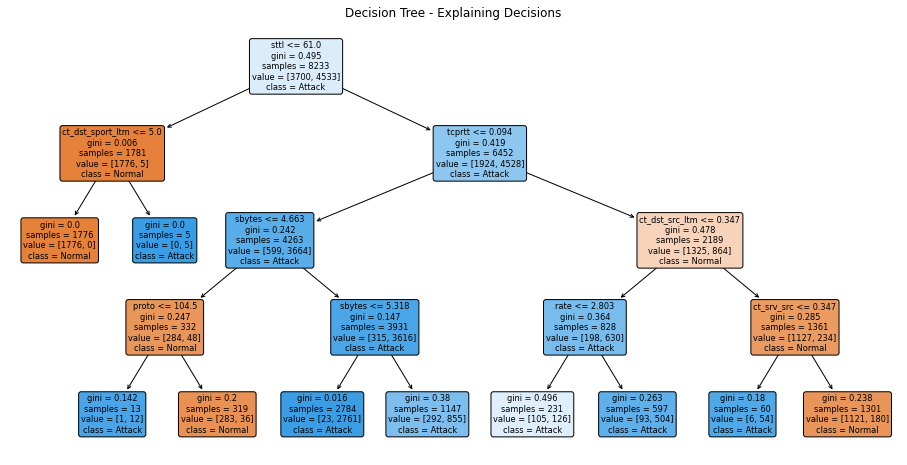

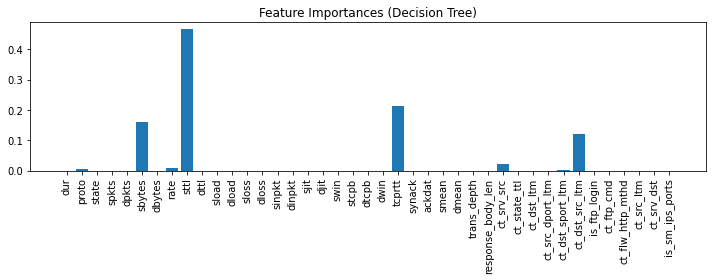

In [13]:
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(train_x, train_y_b)
y_pred_dt = dt.predict(test_x)

plt.figure(figsize=(16,8))
plot_tree(dt, feature_names=train_x.columns, class_names=['Normal','Attack'], filled=True, rounded=True)
plt.title('Decision Tree - Explaining Decisions')
plt.show()

importances = dt.feature_importances_
plt.figure(figsize=(10,4))
plt.bar(range(train_x.shape[1]), importances)
plt.xticks(range(train_x.shape[1]), train_x.columns, rotation=90)
plt.title("Feature Importances (Decision Tree)")
plt.tight_layout()
plt.show()

Support Vector Machines (SVMs) are less directly interpretable than decision trees, but permutation feature importance can be used to quantify the effect of each feature on predictive performance, providing an empirical measure of feature relevance with respect to the learned decision boundary.

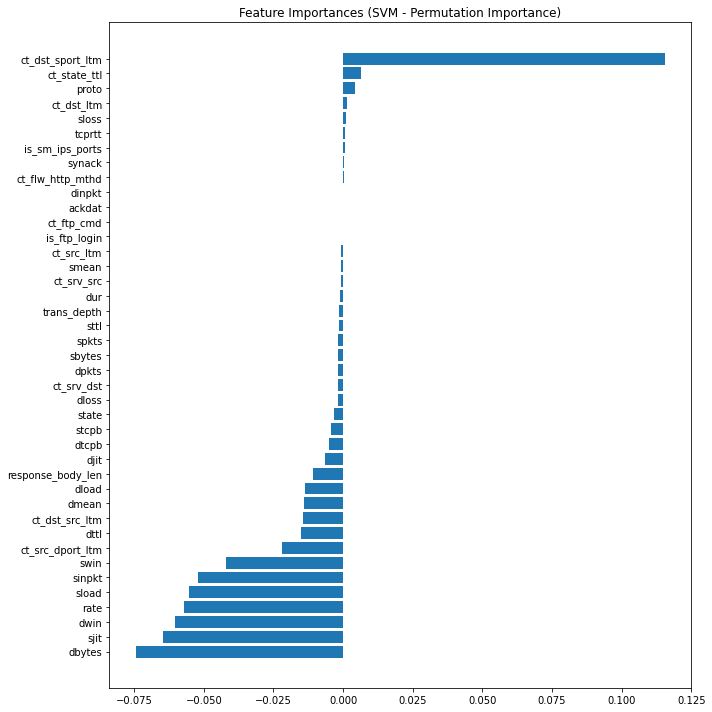

In [14]:
from sklearn.inspection import permutation_importance

svm = SVC(kernel='linear', probability=True, random_state=42)
svm.fit(train_x, train_y_b)
y_pred_svm = svm.predict(test_x)

# Permutation Importance for Explainability
result = permutation_importance(svm, test_x, test_y_b, n_repeats=5, random_state=42)
sorted_idx = result.importances_mean.argsort()

plt.figure(figsize=(10,10))
plt.barh(range(len(sorted_idx)), result.importances_mean[sorted_idx])
plt.yticks(range(len(sorted_idx)), np.array(train_x.columns)[sorted_idx])
plt.title("Feature Importances (SVM - Permutation Importance)")
plt.tight_layout()
plt.show()

Similarly, k-Nearest Neighbours (kNN) does not yield a simple global parametric form, but permutation feature importance can be applied to estimate how sensitive kNN predictions are to each feature, providing a quantitative ranking of feature relevance.

KNN Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.92      0.84     56000
           1       0.96      0.88      0.92    119341

    accuracy                           0.89    175341
   macro avg       0.87      0.90      0.88    175341
weighted avg       0.90      0.89      0.89    175341



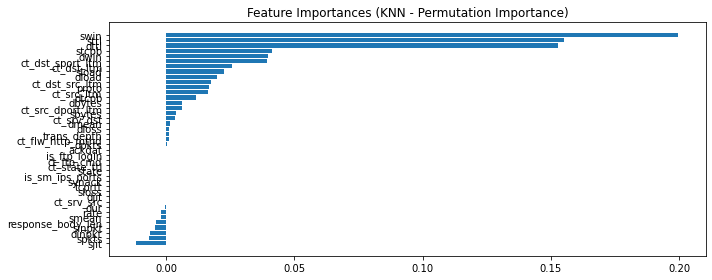

In [15]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(train_x, train_y_b)
y_pred_knn = knn.predict(test_x)

print("KNN Classification Report:")
print(classification_report(test_y_b, y_pred_knn))

# Permutation importance for KNN
result_knn = permutation_importance(knn, test_x, test_y_b, n_repeats=5, random_state=42)
sorted_idx_knn = result_knn.importances_mean.argsort()

plt.figure(figsize=(10,4))
plt.barh(range(len(sorted_idx_knn)), result_knn.importances_mean[sorted_idx_knn])
plt.yticks(range(len(sorted_idx_knn)), np.array(train_x.columns)[sorted_idx_knn])
plt.title("Feature Importances (KNN - Permutation Importance)")
plt.tight_layout()
plt.show()

Fuzzy logic models support interpretability by encoding knowledge in the form of linguistic variables and membership functions (e.g., Low, Medium, High). The degree of membership and the associated rule base make it possible to describe how features contribute to an output, offering a transparent account of feature relevance and decision rationale.

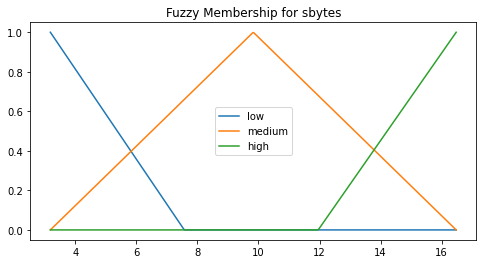

In [16]:
# Example on 'sbytes' with fuzzy logic
import skfuzzy as fuzz

feature = 'sbytes'
x_feature = train_x[feature].values

x_min, x_max = x_feature.min(), x_feature.max()
x_range = np.linspace(x_min, x_max, 500)

# Fuzzy membership: Low, Medium, High
lo = fuzz.trimf(x_range, [x_min, x_min, np.percentile(x_range, 33)])
md = fuzz.trimf(x_range, [x_min, np.percentile(x_range, 50), x_max])
hi = fuzz.trimf(x_range, [np.percentile(x_range, 66), x_max, x_max])

plt.figure(figsize=(8,4))
plt.plot(x_range, lo, label='low')
plt.plot(x_range, md, label='medium')
plt.plot(x_range, hi, label='high')
plt.title(f'Fuzzy Membership for {feature}')
plt.legend()
plt.show()